In [ ]:
Part5
Tsegeb0956

Student ID: tsegeb0956
Date: November 8, 2026

Dataset loaded: Happiness_Development_Index.xlsx

One-hot encoding completed.
Number of features: 193

Training rows: 133
Testing rows: 57

Linear Regression model trained successfully!

MODEL PERFORMANCE
MAE: 0.01653
MSE: 0.00055
R-squared: 0.97102

FEATURE IMPORTANCE (Ranked)
                                   Feature   Coefficient   Importance
                 Country_Equatorial Guinea  5.866824e-02 5.866824e-02
                           Country_Burundi -5.683031e-02 5.683031e-02
             Country_Eswatini (Kingdom of)  4.806181e-02 4.806181e-02
                            Country_Guyana  4.604061e-02 4.604061e-02
                         Country_Australia -4.460084e-02 4.460084e-02
                        Country_Tajikistan -4.277957e-02 4.277957e-02
                            Country_Kuwait  4.194219e-02 4.194219e-02
                            Country_Bhutan  4.099879e-02 4.099879e-02
Country_Venezuela (Bolivarian Republic of) -

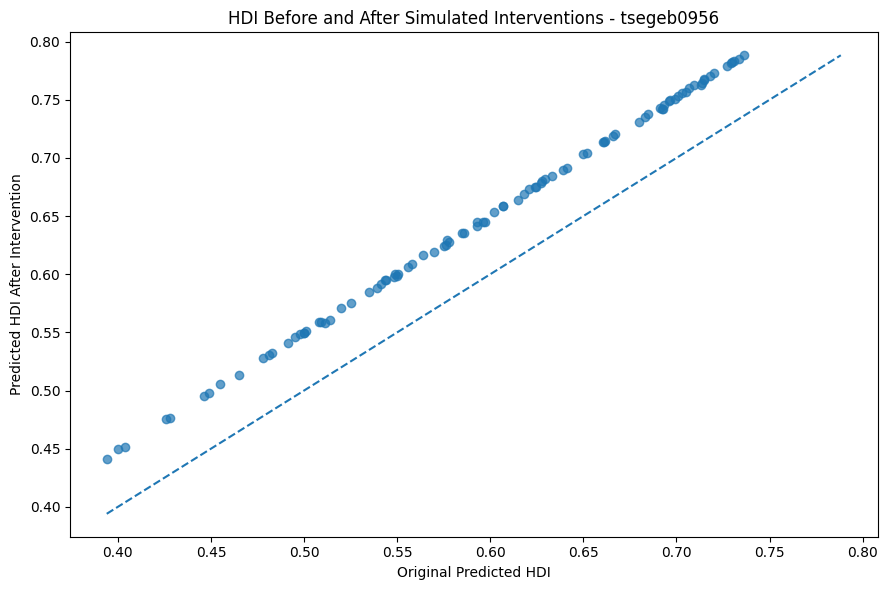

In [4]:

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# STUDENT INFORMATION
STUDENT_ID = "tsegeb0956"
DATE = "November 8, 2026"

print("Student ID:", STUDENT_ID)
print("Date:", DATE)

# 1. LOAD THE HDI DATASET
files = [
    f for f in Path(".").glob("*")
    if f.suffix.lower() in [".csv", ".xlsx", ".xls"]
    and any(word in f.name.lower()
            for word in ["happiness", "development", "hdi"])
]

if not files:
    raise FileNotFoundError("HDI dataset not found in this folder.")

file_path = files[0]

if file_path.suffix.lower() == ".csv":
    df = pd.read_csv(file_path, sep=None, engine="python")
else:
    df = pd.read_excel(file_path)

df.columns = df.columns.str.strip()

print("\nDataset loaded:", file_path.name)

# 2. SELECT FEATURES AND TARGET
column_options = {
    "HDI": ["Human Development Index (HDI)", "HDI"],
    "Life expectancy": ["Life expectancy at birth"],
    "Expected schooling": ["Expected years of schooling"],
    "Mean schooling": ["Mean years of schooling"],
    "GNI": [
        "Gross national income (GNI) per capita",
        "GNI per capita"
    ]
}

def find_column(options):
    for name in options:
        if name in df.columns:
            return name
    raise ValueError(f"Column not found: {options}")

hdi_col = find_column(column_options["HDI"])
life_col = find_column(column_options["Life expectancy"])
expected_col = find_column(column_options["Expected schooling"])
mean_col = find_column(column_options["Mean schooling"])
gni_col = find_column(column_options["GNI"])

numeric_cols = [hdi_col, life_col, expected_col, mean_col, gni_col]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

df = df.dropna(subset=numeric_cols + ["Country"])

# 3. ONE-HOT ENCODING
X = df[[life_col, expected_col, mean_col, gni_col]].copy()
X["Country"] = df["Country"].astype(str)

X = pd.get_dummies(
    X, columns=["Country"], drop_first=True, dtype=int
)

y = df[hdi_col]

print("\nOne-hot encoding completed.")
print("Number of features:", X.shape[1])

# 4. SPLIT INTO TRAINING AND TESTING SETS
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# 5. TRAIN THE LINEAR REGRESSION MODEL
model = LinearRegression()
model.fit(X_train, y_train)

print("\nLinear Regression model trained successfully!")

# 6. MAKE PREDICTIONS AND EVALUATE PERFORMANCE
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("\nMODEL PERFORMANCE")
print("MAE:", round(mae, 5))
print("MSE:", round(mse, 5))
print("R-squared:", round(r2, 5))

# 7. FEATURE IMPORTANCE
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_,
    "Importance": np.abs(model.coef_)
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print("\nFEATURE IMPORTANCE (Ranked)")
print(importance.to_string(index=False))

# 8. LIFE EXPECTANCY EFFECT
life_index = list(X.columns).index(life_col)

print("\nLIFE EXPECTANCY EFFECT")
print("Life expectancy coefficient:",
      round(model.coef_[life_index], 5))

if model.coef_[life_index] > 0:
    print("Higher life expectancy increases predicted HDI.")
elif model.coef_[life_index] < 0:
    print("Higher life expectancy decreases predicted HDI.")
else:
    print("Life expectancy has no linear effect in this model.")

print("\nStudent ID:", STUDENT_ID)
print("Analysis completed!")

# PART 5: SIMULATE INTERVENTIONS

# Select countries with HDI below the median
median_hdi = df[hdi_col].median()
low_hdi = df[df[hdi_col] < median_hdi].copy()

# Prepare the original features
X_intervention = low_hdi[
    [life_col, expected_col, mean_col, gni_col]
].copy()

X_intervention["Country"] = low_hdi["Country"].astype(str)

# Apply the same one-hot encoding used in Part 4
X_intervention = pd.get_dummies(
    X_intervention,
    columns=["Country"],
    drop_first=True,
    dtype=int
)

# Match the features used to train the model
X_intervention = X_intervention.reindex(
    columns=X.columns, fill_value=0
)

# Predict original HDI
low_hdi["Original Predicted HDI"] = model.predict(
    X_intervention
)

# Increase life expectancy by 5%
X_intervention[life_col] = (
    X_intervention[life_col] * 1.05
)

# Increase mean years of schooling by 1.5 years
X_intervention[mean_col] = (
    X_intervention[mean_col] + 1.5
)

# Predict HDI after interventions
low_hdi["Predicted HDI after intervention"] = model.predict(
    X_intervention
)

# Calculate the difference
low_hdi["HDI Improvement"] = (
    low_hdi["Predicted HDI after intervention"]
    - low_hdi["Original Predicted HDI"]
)

print("INTERVENTION RESULTS")
print("Countries included:", len(low_hdi))
print("\nAverage original predicted HDI:",
      round(low_hdi["Original Predicted HDI"].mean(), 4))

print("Average HDI after intervention:",
      round(low_hdi["Predicted HDI after intervention"].mean(), 4))

print("Average predicted improvement:",
      round(low_hdi["HDI Improvement"].mean(), 4))

print("\nCountry-by-country results:")
print(low_hdi[[
    "Country",
    "Original Predicted HDI",
    "Predicted HDI after intervention",
    "HDI Improvement"
]].to_string(index=False))

# PART 5: SCATTER PLOT BEFORE AND AFTER INTERVENTIONS

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    low_hdi["Original Predicted HDI"],
    low_hdi["Predicted HDI after intervention"],
    alpha=0.7
)

# Reference line showing no change
minimum = min(
    low_hdi["Original Predicted HDI"].min(),
    low_hdi["Predicted HDI after intervention"].min()
)

maximum = max(
    low_hdi["Original Predicted HDI"].max(),
    low_hdi["Predicted HDI after intervention"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("HDI Before and After Simulated Interventions - tsegeb0956")
plt.xlabel("Original Predicted HDI")
plt.ylabel("Predicted HDI After Intervention")

plt.tight_layout()
plt.show()


